Using device for PDE solving: cuda
Will save dataset to: /kaggle/working/all8families_box_linear_id_ampood_recorded.mat

Canonical 8 families:
  family1: flux_type=1, viscous=True
  family2: flux_type=1, viscous=False
  family3: flux_type=2, viscous=True
  family4: flux_type=2, viscous=False
  family5: flux_type=3, viscous=True
  family6: flux_type=3, viscous=False
  family7: flux_type=4, viscous=True
  family8: flux_type=4, viscous=False

GENERATING PAIRED ID + OOD DATA
All regimes share center/width/eps_box/amp_unit at each sample index.
Only amplitude mapping changes between regimes.
Saved uc is DIRECT linear 50->100.


Families:   0%|          | 0/8 [00:00<?, ?it/s]

family1:   0%|          | 0/100 [00:00<?, ?it/s]


Linear-equivalence audit max |direct-oldroute| = 0.000e+00
finished family1 | elapsed=9.15 min | joint accept=1.000


family2:   0%|          | 0/100 [00:00<?, ?it/s]

finished family2 | elapsed=13.05 min | joint accept=1.000


... (8 outputs left out)

family7:   0%|          | 0/100 [00:00<?, ?it/s]

finished family7 | elapsed=48.25 min | joint accept=1.000


family8:   0%|          | 0/100 [00:00<?, ?it/s]

finished family8 | elapsed=52.18 min | joint accept=1.000

FINAL DATASET DIAGNOSTICS
Joint acceptance rate: overall=1.000000, min/op=1.000000, mean/op=1.000000, max/op=1.000000
  id: amp=[0.800012, 1.499988] | uc-uf RelL2 mean=37.263% | median=30.426% | std=25.061%
near: amp=[1.500001, 1.569999] | uc-uf RelL2 mean=32.631% | median=24.909% | std=24.141%
wide: amp=[1.500003, 1.649997] | uc-uf RelL2 mean=32.256% | median=24.402% | std=24.129%
 far: amp=[1.570001, 1.649999] | uc-uf RelL2 mean=31.912% | median=23.943% | std=24.128%
Paired-IC geometry checks: PASS


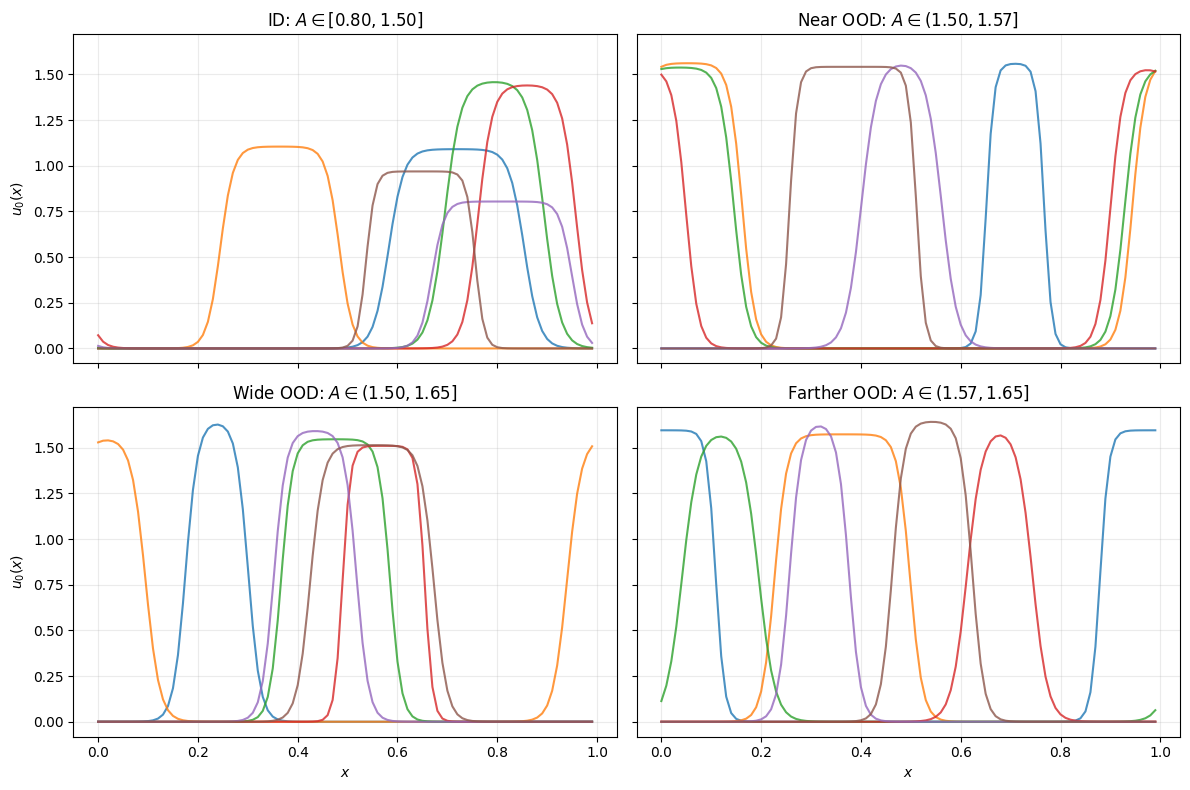

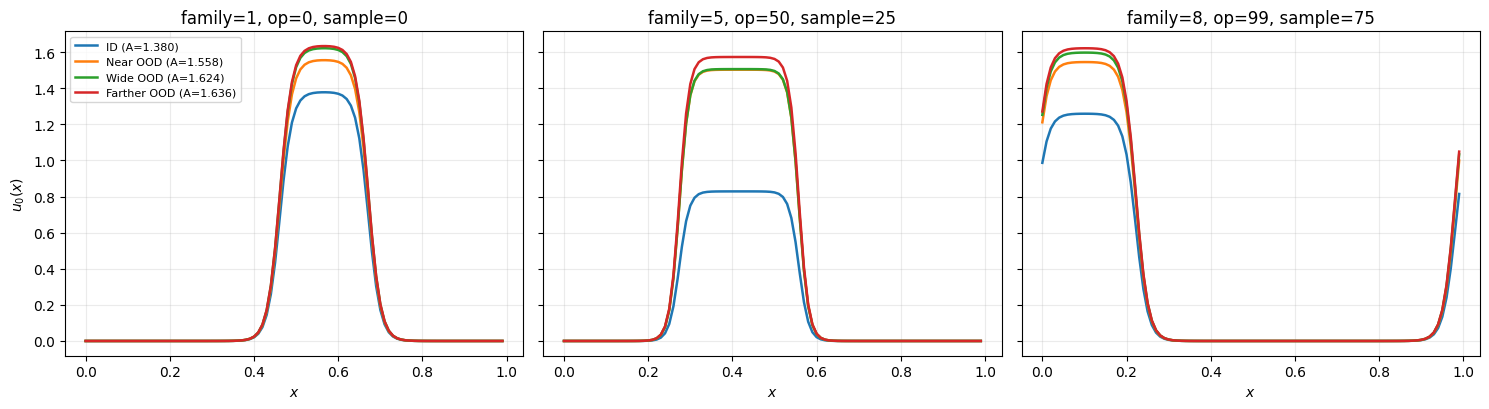


Saved IC comparison plots:
  /kaggle/working/box_ic_id_ood_regime_examples.png
  /kaggle/working/box_ic_id_ood_regime_examples.pdf
  /kaggle/working/box_ic_id_ood_paired_examples.png
  /kaggle/working/box_ic_id_ood_paired_examples.pdf

Saving large MAT dataset ...
Saved: /kaggle/working/all8families_box_linear_id_ampood_recorded.mat
Saved manifest: /kaggle/working/all8families_box_linear_id_ampood_recorded_manifest.json

FINAL SHAPES
operators: (8, 100, 3)
pair_id: (8, 100, 100)
ic_base_params: (8, 100, 100, 4)
id u0 (8, 100, 100, 100) uc50 (8, 100, 100, 50) uc (8, 100, 100, 100) uf (8, 100, 100, 100) params (8, 100, 100, 4)
near u0 (8, 100, 100, 100) uc50 (8, 100, 100, 50) uc (8, 100, 100, 100) uf (8, 100, 100, 100) params (8, 100, 100, 4)
wide u0 (8, 100, 100, 100) uc50 (8, 100, 100, 50) uc (8, 100, 100, 100) uf (8, 100, 100, 100) params (8, 100, 100, 4)
far u0 (8, 100, 100, 100) uc50 (8, 100, 100, 50) uc (8, 100, 100, 100) uf (8, 100, 100, 100) params (8, 100, 100, 4)

DONE


In [1]:
# ============================================================
# KAGGLE ONE-CELL DATASET GENERATOR
# BURGERS-TYPE / 8 FAMILIES / SMOOTH BOX IC
# DIRECT LINEAR COARSE REPRESENTATION + FULL IC RECORDING
# ID + AMPLITUDE-OOD REGIMES
# ============================================================
#
# PURPOSE
# -------
# Rebuild the full box-IC dataset in a form that is directly consistent
# with the linear coarse input used by the trained ICL model.
#
# IMPORTANT CHANGES RELATIVE TO THE OLD GENERATOR
# ------------------------------------------------
# 1) Low-fidelity PDE is still solved on NX_LO=50.
# 2) The saved/model-facing uc is now DIRECTLY linearly interpolated
#    from 50 -> 100 using torch.nn.functional.interpolate(...,
#    mode='linear', align_corners=False).
# 3) The raw 50-point low-fidelity state is ALSO saved as uc50.
# 4) Every accepted sample saves its exact initial condition u0 and
#    parameters [center, width, amplitude, eps_box].
# 5) All ID/OOD regimes are PAIRED sample-by-sample:
#       same family, same operator, same sample index,
#       same center, width, eps_box, and amplitude quantile;
#       only the amplitude range changes.
# 6) A unique pair_id is saved for every [family, operator, sample].
#
# REGIMES
# -------
# ID:           A in [0.80, 1.50]
# Near OOD:     A in (1.50, 1.57]
# Wide OOD:     A in (1.50, 1.65]
# Farther OOD:  A in (1.57, 1.65]
#
# MAIN OUTPUT
# -----------
# /kaggle/working/all8families_box_linear_id_ampood_recorded.mat
#
# MAIN KEYS
# ---------
# operators                  (8,100,3)
# x                          (100,)
# pair_id                    (8,100,100)
# ic_base_params             (8,100,100,4)
#                            [center, width, eps_box, amp_unit]
#
# For each regime R in {id, near, wide, far}:
#   u0_R                     (8,100,100,100)
#   uc50_R                   (8,100,100,50)
#   uc_R                     (8,100,100,100)  <-- DIRECT LINEAR 50->100
#   uf_R                     (8,100,100,100)
#   ic_params_R              (8,100,100,4)
#                            [center, width, amplitude, eps_box]
#
# Backward-compatible ID aliases are also saved:
#   u0, uc50, uc, uf, ic_params
#
# The same [fam, op, sample] index refers to the paired sample across
# ALL arrays and ALL regimes.
# ============================================================

import os
import time
import json
from pathlib import Path

import numpy as np
import scipy.io as sio
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm


# ============================================================
# 0. SETTINGS
# ============================================================
SEED = 42
rng = np.random.default_rng(SEED)

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device for PDE solving:", DEVICE)

SAVE_DIR = Path("/kaggle/working")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

OUT_FILE = SAVE_DIR / "all8families_box_linear_id_ampood_recorded.mat"
META_JSON = SAVE_DIR / "all8families_box_linear_id_ampood_recorded_manifest.json"
IC_PANEL_PNG = SAVE_DIR / "box_ic_id_ood_regime_examples.png"
IC_PANEL_PDF = SAVE_DIR / "box_ic_id_ood_regime_examples.pdf"
IC_PAIRED_PNG = SAVE_DIR / "box_ic_id_ood_paired_examples.png"
IC_PAIRED_PDF = SAVE_DIR / "box_ic_id_ood_paired_examples.pdf"

print("Will save dataset to:", OUT_FILE)

# Time / grids
T_FINAL = 2.0
NX_HI = 100
NX_LO = 50
NX_STORE = 100
assert NX_STORE == NX_HI
assert NX_HI == 2 * NX_LO

x_hi = np.linspace(0.0, 1.0, NX_HI, endpoint=False, dtype=np.float32)
dx_hi = float(x_hi[1] - x_hi[0])
dx_lo = 1.0 / NX_LO

# Dataset size
N_FAMILIES = 8
N_OPS_PER_FAM = 100
N_SAMPLES = 100
GEN_BATCH_MIN = 32

# Solver constants
U_CLIP = 6.0
CFL_UC = 0.90
CFL_UF = 0.45
UC_NU_CONST = 0.0
UC_NU_SHOCK = 6e-4

# Operator ranges
Q1_MIN = 0.5
Q1_MAX = 2.0
Q2_MIN = 0.005
Q2_MAX = 0.02

# IC geometry ranges
C_MIN, C_MAX = 0.0, 1.0
W_MIN, W_MAX = 0.10, 0.30
EPS_MIN, EPS_MAX = 0.015, 0.035

# Mild rejection threshold
UF_NORM_MIN = 0.15

# Regimes. amp_unit in [0,1) is mapped into each interval.
REGIMES = {
    "id": {
        "label": "ID",
        "amp_min": 0.80,
        "amp_max": 1.50,
        "left_open": False,
    },
    "near": {
        "label": "Near OOD",
        "amp_min": 1.50,
        "amp_max": 1.57,
        "left_open": True,
    },
    "wide": {
        "label": "Wide OOD",
        "amp_min": 1.50,
        "amp_max": 1.65,
        "left_open": True,
    },
    "far": {
        "label": "Farther OOD",
        "amp_min": 1.57,
        "amp_max": 1.65,
        "left_open": True,
    },
}
REGIME_ORDER = ["id", "near", "wide", "far"]


# ============================================================
# 1. IC PARAMETER SAMPLING
# ============================================================
def sample_base_params_old_rng_order(n):
    """
    Draw base IC parameters in the SAME scalar RNG-call order as the old
    smooth-box generator:
        center -> width -> amplitude random number -> eps_box
    for each sample.

    The third draw is stored as amp_unit and mapped into each amplitude
    regime. For the ID regime, amplitude = 0.8 + 0.7*amp_unit, which
    reproduces the old sampling formula when acceptance is unchanged.

    Returns
    -------
    base : (n,4) float32
        columns [center, width, eps_box, amp_unit]
    """
    base = np.zeros((n, 4), dtype=np.float32)
    for i in range(n):
        c = rng.random()
        w = W_MIN + (W_MAX - W_MIN) * rng.random()
        amp_unit = rng.random()
        eps_box = EPS_MIN + (EPS_MAX - EPS_MIN) * rng.random()
        base[i] = [c, w, eps_box, amp_unit]
    return base


def map_amp(amp_unit, cfg):
    low = float(cfg["amp_min"])
    high = float(cfg["amp_max"])
    if cfg["left_open"]:
        low = float(np.nextafter(np.float64(low), np.float64(np.inf)))
    return low + (high - low) * amp_unit


def build_u0_from_base(xg, base_params, regime_cfg):
    """
    Build one regime's ICs from shared base geometry.

    Returns
    -------
    u0_np : (n,100) float32
    params: (n,4) float32 [center,width,amplitude,eps_box]
    """
    n = base_params.shape[0]
    u0 = np.zeros((n, len(xg)), dtype=np.float32)
    params = np.zeros((n, 4), dtype=np.float32)

    for i in range(n):
        c, w, eps_box, amp_unit = [float(v) for v in base_params[i]]
        amp = float(map_amp(amp_unit, regime_cfg))

        x_shift = ((xg - c + 0.5) % 1.0) - 0.5
        left = -w / 2.0
        right = w / 2.0

        profile = 0.5 * amp * (
            np.tanh((x_shift - left) / eps_box)
            - np.tanh((x_shift - right) / eps_box)
        )

        u0[i] = profile.astype(np.float32)
        params[i] = [c, w, amp, eps_box]

    return u0, params


# ============================================================
# 2. FLUX DEFINITIONS
# ============================================================
def get_flux_torch(flux_type: int):
    if flux_type == 1:
        return (lambda u: 0.5 * u**2), (lambda u: u)
    elif flux_type == 2:
        return (lambda u: (1.0 / 3.0) * u**3), (lambda u: u**2)
    elif flux_type == 3:
        return (lambda u: torch.sin(u)), (lambda u: torch.cos(u))
    elif flux_type == 4:
        return (lambda u: u), (lambda u: torch.ones_like(u))
    else:
        raise ValueError(f"Unknown flux_type={flux_type}")


def rusanov_flux(uL, uR, flux, dflux):
    a = torch.maximum(torch.abs(dflux(uL)), torch.abs(dflux(uR)))
    return 0.5 * (flux(uL) + flux(uR)) - 0.5 * a * (uR - uL)


def hll_flux(uL, uR, flux, dflux):
    aL = dflux(uL)
    aR = dflux(uR)
    sL = torch.minimum(aL, aR)
    sR = torch.maximum(aL, aR)

    fL = flux(uL)
    fR = flux(uR)

    denom = (sR - sL) + 1e-12
    fHLL = (sR * fL - sL * fR + sL * sR * (uR - uL)) / denom

    return torch.where(
        sL >= 0.0,
        fL,
        torch.where(sR <= 0.0, fR, fHLL),
    )


# ============================================================
# 3. LOW-FIDELITY SOLVER (50 POINTS)
# ============================================================
def solve_uc_hll_shockvisc(u0, q1, flux, dflux, dx, t_final):
    u = u0.clone()
    t = 0.0

    while t < t_final:
        amax = torch.amax(torch.abs(dflux(u)))
        amax_f = max(float(amax.detach().cpu().item()), 1e-12)
        dt_adv = CFL_UC * dx / (q1 * amax_f) if q1 != 0.0 else float("inf")

        if (UC_NU_CONST > 0.0) or (UC_NU_SHOCK > 0.0):
            uR = torch.roll(u, -1, -1)
            uL = torch.roll(u, 1, -1)

            sensor = torch.abs(uR - 2.0 * u + uL)
            smax = torch.amax(sensor, dim=1, keepdim=True) + 1e-12
            sensor_n = sensor / smax

            nu_eff = UC_NU_CONST + UC_NU_SHOCK * sensor_n
            nu_max = float(torch.amax(nu_eff).detach().cpu().item())
            dt_diff = (
                CFL_UC * dx * dx / (2.0 * nu_max)
                if nu_max > 0.0
                else float("inf")
            )
        else:
            nu_eff = 0.0
            nu_max = 0.0
            dt_diff = float("inf")

        dt = min(dt_adv, dt_diff, t_final - t)

        uR = torch.roll(u, -1, -1)
        F_ip12 = hll_flux(u, uR, flux, dflux)
        F_im12 = torch.roll(F_ip12, 1, -1)
        u_new = u - (q1 * dt / dx) * (F_ip12 - F_im12)

        if nu_max > 0.0:
            uL = torch.roll(u, 1, -1)
            lap = (uR - 2.0 * u + uL) / (dx * dx)
            u_new = u_new + dt * nu_eff * lap

        u = torch.clamp(u_new, -U_CLIP, U_CLIP)
        t += dt

    return u


# ============================================================
# 4. HIGH-FIDELITY SOLVER (100 POINTS)
# ============================================================
def superbee_limiter(r):
    term1 = torch.clamp(2.0 * r, max=1.0)
    term2 = torch.clamp(r, max=2.0)
    return torch.clamp(torch.maximum(term1, term2), min=0.0)


def muscl_slopes_superbee(u):
    du_b = u - torch.roll(u, 1, -1)
    du_f = torch.roll(u, -1, -1) - u
    r = torch.where(
        torch.abs(du_f) > 1e-12,
        du_b / (du_f + 1e-14),
        torch.zeros_like(u),
    )
    phi = superbee_limiter(r)
    return phi * du_f


def solve_uf_muscl_hancock(u0, q1, q2, flux, dflux, dx, t_final):
    u = u0.clone()
    t = 0.0

    while t < t_final:
        amax = torch.amax(torch.abs(dflux(u)))
        amax_f = max(float(amax.detach().cpu().item()), 1e-12)

        dt_adv = CFL_UF * dx / (q1 * amax_f) if q1 != 0.0 else float("inf")
        dt_diff = CFL_UF * dx * dx / (2.0 * q2) if q2 > 0.0 else float("inf")
        dt = min(dt_adv, dt_diff, t_final - t)

        du = muscl_slopes_superbee(u)
        uL_ip12 = u + 0.5 * du
        uR_ip12 = torch.roll(u, -1, -1) - 0.5 * torch.roll(du, -1, -1)

        F_ip12 = rusanov_flux(uL_ip12, uR_ip12, flux, dflux)
        F_im12 = torch.roll(F_ip12, 1, -1)

        u_half = u - (q1 * dt / (2.0 * dx)) * (F_ip12 - F_im12)
        if q2 > 0.0:
            uR = torch.roll(u, -1, -1)
            uL = torch.roll(u, 1, -1)
            lap = (uR - 2.0 * u + uL) / (dx * dx)
            u_half = u_half + q2 * (dt / 2.0) * lap

        u_half = torch.clamp(u_half, -U_CLIP, U_CLIP)

        du_h = muscl_slopes_superbee(u_half)
        uLh_ip12 = u_half + 0.5 * du_h
        uRh_ip12 = torch.roll(u_half, -1, -1) - 0.5 * torch.roll(du_h, -1, -1)

        Fh_ip12 = rusanov_flux(uLh_ip12, uRh_ip12, flux, dflux)
        Fh_im12 = torch.roll(Fh_ip12, 1, -1)

        u_new = u - (q1 * dt / dx) * (Fh_ip12 - Fh_im12)
        if q2 > 0.0:
            uR = torch.roll(u_half, -1, -1)
            uL = torch.roll(u_half, 1, -1)
            lap = (uR - 2.0 * u_half + uL) / (dx * dx)
            u_new = u_new + q2 * dt * lap

        u = torch.clamp(u_new, -U_CLIP, U_CLIP)
        t += dt

    return u


# ============================================================
# 5. DIRECT LINEAR COARSE REPRESENTATION
# ============================================================
def uc50_to_uc100_linear(uc50_batch):
    """Exact model-facing linear interpolation: 50 -> 100."""
    return F.interpolate(
        uc50_batch.unsqueeze(1),
        size=NX_STORE,
        mode="linear",
        align_corners=False,
    ).squeeze(1)


def old_repeat_then_deblock_linear(uc50_batch):
    """Audit-only reproduction of the old training preprocessing."""
    repeated = uc50_batch.repeat_interleave(2, dim=1)
    t50 = 0.5 * (repeated[:, 0::2] + repeated[:, 1::2])
    return F.interpolate(
        t50.unsqueeze(1),
        size=NX_STORE,
        mode="linear",
        align_corners=False,
    ).squeeze(1)


# ============================================================
# 6. FAMILIES + OPERATORS
# ============================================================
FLUX_TYPES = [1, 2, 3, 4]
VISCOUS_FLAGS = [True, False]
families = [(ft, visc) for ft in FLUX_TYPES for visc in VISCOUS_FLAGS]

original_family_ids = np.arange(1, 9, dtype=np.int32)
family_table = np.array(
    [[float(ft), float(visc)] for ft, visc in families],
    dtype=np.float32,
)

print("\nCanonical 8 families:")
for k, (ft, visc) in enumerate(families, start=1):
    print(f"  family{k}: flux_type={ft}, viscous={visc}")

# IMPORTANT: same operator sampling order as the old generator.
operators = np.zeros((N_FAMILIES, N_OPS_PER_FAM, 3), dtype=np.float32)
for fam_idx, (flux_type, viscous) in enumerate(families):
    for op_idx in range(N_OPS_PER_FAM):
        q1 = rng.uniform(Q1_MIN, Q1_MAX)
        q2 = rng.uniform(Q2_MIN, Q2_MAX) if viscous else 0.0
        operators[fam_idx, op_idx] = [q1, q2, float(flux_type)]


# ============================================================
# 7. ALLOCATE ALL REGIMES
# ============================================================
SHAPE_100 = (N_FAMILIES, N_OPS_PER_FAM, N_SAMPLES, NX_STORE)
SHAPE_50 = (N_FAMILIES, N_OPS_PER_FAM, N_SAMPLES, NX_LO)
SHAPE_PARAM = (N_FAMILIES, N_OPS_PER_FAM, N_SAMPLES, 4)

store = {}
for regime in REGIME_ORDER:
    store[regime] = {
        "u0": np.zeros(SHAPE_100, dtype=np.float32),
        "uc50": np.zeros(SHAPE_50, dtype=np.float32),
        "uc": np.zeros(SHAPE_100, dtype=np.float32),
        "uf": np.zeros(SHAPE_100, dtype=np.float32),
        "ic_params": np.zeros(SHAPE_PARAM, dtype=np.float32),
    }

# Common across regimes for paired samples:
# [center, width, eps_box, amp_unit]
ic_base_params = np.zeros(SHAPE_PARAM, dtype=np.float32)
pair_id = np.zeros((N_FAMILIES, N_OPS_PER_FAM, N_SAMPLES), dtype=np.int64)

accepted_counts = np.zeros((N_FAMILIES, N_OPS_PER_FAM), dtype=np.int32)
generated_counts = np.zeros((N_FAMILIES, N_OPS_PER_FAM), dtype=np.int32)


# ============================================================
# 8. GENERATE PAIRED ID/OOD DATA
# ============================================================
print("\n" + "=" * 100)
print("GENERATING PAIRED ID + OOD DATA")
print("All regimes share center/width/eps_box/amp_unit at each sample index.")
print("Only amplitude mapping changes between regimes.")
print("Saved uc is DIRECT linear 50->100.")
print("=" * 100)

start = time.time()
torch.set_grad_enabled(False)

linear_equivalence_checked = False

for fam_idx, (flux_type, viscous) in enumerate(tqdm(families, desc="Families")):
    flux, dflux = get_flux_torch(int(flux_type))

    for op_idx in tqdm(range(N_OPS_PER_FAM), desc=f"family{fam_idx+1}", leave=False):
        q1, q2, _ = operators[fam_idx, op_idx]
        q1 = float(q1)
        q2 = float(q2)

        kept_base = []
        kept_by_regime = {
            r: {"u0": [], "uc50": [], "uc": [], "uf": [], "params": []}
            for r in REGIME_ORDER
        }
        n_kept = 0

        while n_kept < N_SAMPLES:
            need = N_SAMPLES - n_kept
            batch_size = max(GEN_BATCH_MIN, need)

            base = sample_base_params_old_rng_order(batch_size)
            generated_counts[fam_idx, op_idx] += batch_size

            batch_results = {}
            joint_good = np.ones(batch_size, dtype=bool)

            for regime in REGIME_ORDER:
                u0_np, params_np = build_u0_from_base(x_hi, base, REGIMES[regime])
                u0_hi = torch.tensor(u0_np, dtype=torch.float32, device=DEVICE)
                u0_lo = 0.5 * (u0_hi[:, 0::2] + u0_hi[:, 1::2])

                with torch.no_grad():
                    uc50_t = solve_uc_hll_shockvisc(
                        u0_lo, q1, flux, dflux, dx_lo, T_FINAL
                    )
                    uf100_t = solve_uf_muscl_hancock(
                        u0_hi, q1, q2, flux, dflux, dx_hi, T_FINAL
                    )
                    uc100_t = uc50_to_uc100_linear(uc50_t)

                if not linear_equivalence_checked:
                    audit = old_repeat_then_deblock_linear(uc50_t)
                    max_diff = float(torch.max(torch.abs(audit - uc100_t)).cpu().item())
                    print(f"\nLinear-equivalence audit max |direct-oldroute| = {max_diff:.3e}")
                    assert max_diff < 1e-7
                    linear_equivalence_checked = True

                uc50_np = uc50_t.detach().cpu().numpy().astype(np.float32)
                uc100_np = uc100_t.detach().cpu().numpy().astype(np.float32)
                uf100_np = uf100_t.detach().cpu().numpy().astype(np.float32)

                good = np.linalg.norm(uf100_np, axis=1) >= UF_NORM_MIN
                joint_good &= good

                batch_results[regime] = {
                    "u0": u0_np,
                    "uc50": uc50_np,
                    "uc": uc100_np,
                    "uf": uf100_np,
                    "params": params_np,
                }

            n_good = int(np.sum(joint_good))
            accepted_counts[fam_idx, op_idx] += n_good

            if n_good > 0:
                kept_base.append(base[joint_good])
                for regime in REGIME_ORDER:
                    for key in ["u0", "uc50", "uc", "uf", "params"]:
                        kept_by_regime[regime][key].append(
                            batch_results[regime][key][joint_good]
                        )
                n_kept += n_good

        base_op = np.concatenate(kept_base, axis=0)[:N_SAMPLES]
        ic_base_params[fam_idx, op_idx] = base_op

        for regime in REGIME_ORDER:
            store[regime]["u0"][fam_idx, op_idx] = np.concatenate(
                kept_by_regime[regime]["u0"], axis=0
            )[:N_SAMPLES]
            store[regime]["uc50"][fam_idx, op_idx] = np.concatenate(
                kept_by_regime[regime]["uc50"], axis=0
            )[:N_SAMPLES]
            store[regime]["uc"][fam_idx, op_idx] = np.concatenate(
                kept_by_regime[regime]["uc"], axis=0
            )[:N_SAMPLES]
            store[regime]["uf"][fam_idx, op_idx] = np.concatenate(
                kept_by_regime[regime]["uf"], axis=0
            )[:N_SAMPLES]
            store[regime]["ic_params"][fam_idx, op_idx] = np.concatenate(
                kept_by_regime[regime]["params"], axis=0
            )[:N_SAMPLES]

        for s in range(N_SAMPLES):
            pair_id[fam_idx, op_idx, s] = (
                (fam_idx * N_OPS_PER_FAM + op_idx) * N_SAMPLES + s
            )

    fam_accept = accepted_counts[fam_idx].sum() / max(
        generated_counts[fam_idx].sum(), 1
    )
    elapsed_min = (time.time() - start) / 60.0
    print(
        f"finished family{fam_idx+1} | "
        f"elapsed={elapsed_min:.2f} min | joint accept={fam_accept:.3f}"
    )


# ============================================================
# 9. DIAGNOSTICS
# ============================================================
accept_rate_per_op = accepted_counts / np.maximum(generated_counts, 1)

print("\n" + "=" * 100)
print("FINAL DATASET DIAGNOSTICS")
print("=" * 100)
print(
    "Joint acceptance rate: "
    f"overall={accepted_counts.sum()/max(generated_counts.sum(),1):.6f}, "
    f"min/op={accept_rate_per_op.min():.6f}, "
    f"mean/op={accept_rate_per_op.mean():.6f}, "
    f"max/op={accept_rate_per_op.max():.6f}"
)

for regime in REGIME_ORDER:
    uc_arr = store[regime]["uc"]
    uf_arr = store[regime]["uf"]
    params = store[regime]["ic_params"]

    rel = np.linalg.norm(uc_arr - uf_arr, axis=-1) / (
        np.linalg.norm(uf_arr, axis=-1) + 1e-8
    )
    amps = params[..., 2]

    print(
        f"{regime:>4s}: amp=[{amps.min():.6f}, {amps.max():.6f}] | "
        f"uc-uf RelL2 mean={100*rel.mean():.3f}% | "
        f"median={100*np.median(rel):.3f}% | std={100*rel.std():.3f}%"
    )

# Pairing assertions
for regime in REGIME_ORDER:
    p = store[regime]["ic_params"]
    assert np.allclose(p[..., 0], ic_base_params[..., 0])  # center
    assert np.allclose(p[..., 1], ic_base_params[..., 1])  # width
    assert np.allclose(p[..., 3], ic_base_params[..., 2])  # eps_box

print("Paired-IC geometry checks: PASS")


# ============================================================
# 10. PLOTS FOR ID/OOD IC COMPARISON
# ============================================================
plot_rng = np.random.default_rng(SEED + 999)

# (A) 2x2 regime panels, multiple examples per regime
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
axes = axes.ravel()

panel_titles = {
    "id": r"ID: $A\in[0.80,1.50]$",
    "near": r"Near OOD: $A\in(1.50,1.57]$",
    "wide": r"Wide OOD: $A\in(1.50,1.65]$",
    "far": r"Farther OOD: $A\in(1.57,1.65]$",
}

for ax, regime in zip(axes, REGIME_ORDER):
    arr = store[regime]["u0"].reshape(-1, NX_STORE)
    params = store[regime]["ic_params"].reshape(-1, 4)
    idxs = plot_rng.choice(arr.shape[0], size=6, replace=False)
    for idx in idxs:
        ax.plot(x_hi, arr[idx], linewidth=1.5, alpha=0.8)
    ax.set_title(panel_titles[regime])
    ax.grid(True, alpha=0.25)

axes[0].set_ylabel(r"$u_0(x)$")
axes[2].set_ylabel(r"$u_0(x)$")
axes[2].set_xlabel(r"$x$")
axes[3].set_xlabel(r"$x$")
fig.tight_layout()
fig.savefig(IC_PANEL_PNG, dpi=300, bbox_inches="tight")
fig.savefig(IC_PANEL_PDF, bbox_inches="tight")
plt.show()

# (B) Paired comparison: same geometry, same amp quantile, four regimes
# Choose three fixed paired IDs for a clean visual audit.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
paired_choices = [(0, 0, 0), (4, 50, 25), (7, 99, 75)]

for ax, (fam, op, s) in zip(axes, paired_choices):
    for regime in REGIME_ORDER:
        amp = store[regime]["ic_params"][fam, op, s, 2]
        ax.plot(
            x_hi,
            store[regime]["u0"][fam, op, s],
            linewidth=1.8,
            label=f"{REGIMES[regime]['label']} (A={amp:.3f})",
        )
    ax.set_title(f"family={fam+1}, op={op}, sample={s}")
    ax.set_xlabel(r"$x$")
    ax.grid(True, alpha=0.25)

axes[0].set_ylabel(r"$u_0(x)$")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(IC_PAIRED_PNG, dpi=300, bbox_inches="tight")
fig.savefig(IC_PAIRED_PDF, bbox_inches="tight")
plt.show()

print("\nSaved IC comparison plots:")
print(" ", IC_PANEL_PNG)
print(" ", IC_PANEL_PDF)
print(" ", IC_PAIRED_PNG)
print(" ", IC_PAIRED_PDF)


# ============================================================
# 11. SAVE MAT FILE
# ============================================================
print("\nSaving large MAT dataset ...")

save_dict = {
    "dataset_name": np.array(
        ["all8families_box_linear_id_ampood_recorded"], dtype=object
    ),
    "seed": np.array([SEED], dtype=np.int32),
    "operators": operators.astype(np.float32),
    "x": x_hi.astype(np.float32),
    "family_table": family_table.astype(np.float32),
    "original_family_ids": original_family_ids.astype(np.int32),
    "pair_id": pair_id.astype(np.int64),
    "ic_base_params": ic_base_params.astype(np.float32),
    "ic_base_param_names": np.array(
        ["center", "width", "eps_box", "amp_unit"], dtype=object
    ),
    "ic_param_names": np.array(
        ["center", "width", "amplitude", "eps_box"], dtype=object
    ),
    "regime_names": np.array(REGIME_ORDER, dtype=object),
    "coarse_representation": np.array(
        ["direct_linear_50_to_100_align_corners_false"], dtype=object
    ),
    "t_final": np.array([T_FINAL], dtype=np.float32),
    "nx_lo": np.array([NX_LO], dtype=np.int32),
    "nx_hi": np.array([NX_HI], dtype=np.int32),
    "nx_store": np.array([NX_STORE], dtype=np.int32),
    "q1_min": np.array([Q1_MIN], dtype=np.float32),
    "q1_max": np.array([Q1_MAX], dtype=np.float32),
    "q2_min": np.array([Q2_MIN], dtype=np.float32),
    "q2_max": np.array([Q2_MAX], dtype=np.float32),
    "uc_nu_const": np.array([UC_NU_CONST], dtype=np.float32),
    "uc_nu_shock": np.array([UC_NU_SHOCK], dtype=np.float32),
    "uf_norm_min_threshold": np.array([UF_NORM_MIN], dtype=np.float32),
    "joint_accept_rate_per_op": accept_rate_per_op.astype(np.float32),
    "box_center_min": np.array([C_MIN], dtype=np.float32),
    "box_center_max": np.array([C_MAX], dtype=np.float32),
    "box_width_min": np.array([W_MIN], dtype=np.float32),
    "box_width_max": np.array([W_MAX], dtype=np.float32),
    "box_eps_min": np.array([EPS_MIN], dtype=np.float32),
    "box_eps_max": np.array([EPS_MAX], dtype=np.float32),
}

for regime in REGIME_ORDER:
    cfg = REGIMES[regime]
    save_dict[f"u0_{regime}"] = store[regime]["u0"].astype(np.float32)
    save_dict[f"uc50_{regime}"] = store[regime]["uc50"].astype(np.float32)
    save_dict[f"uc_{regime}"] = store[regime]["uc"].astype(np.float32)
    save_dict[f"uf_{regime}"] = store[regime]["uf"].astype(np.float32)
    save_dict[f"ic_params_{regime}"] = store[regime]["ic_params"].astype(np.float32)
    save_dict[f"amp_min_{regime}"] = np.array([cfg["amp_min"]], dtype=np.float32)
    save_dict[f"amp_max_{regime}"] = np.array([cfg["amp_max"]], dtype=np.float32)
    save_dict[f"amp_left_open_{regime}"] = np.array(
        [1 if cfg["left_open"] else 0], dtype=np.int32
    )

# Backward-compatible aliases = ID regime
save_dict["u0"] = store["id"]["u0"].astype(np.float32)
save_dict["uc50"] = store["id"]["uc50"].astype(np.float32)
save_dict["uc"] = store["id"]["uc"].astype(np.float32)
save_dict["uf"] = store["id"]["uf"].astype(np.float32)
save_dict["ic_params"] = store["id"]["ic_params"].astype(np.float32)

sio.savemat(OUT_FILE, save_dict, do_compression=False)
print("Saved:", OUT_FILE)

manifest = {
    "dataset": str(OUT_FILE),
    "seed": SEED,
    "shape_per_regime": [N_FAMILIES, N_OPS_PER_FAM, N_SAMPLES, NX_STORE],
    "operators_shape": list(operators.shape),
    "regimes": REGIMES,
    "pairing": (
        "Same [family,operator,sample] uses the same center, width, eps_box, "
        "and amp_unit across all regimes. Only amplitude mapping changes."
    ),
    "ic_params_order": ["center", "width", "amplitude", "eps_box"],
    "ic_base_params_order": ["center", "width", "eps_box", "amp_unit"],
    "coarse_solver_grid": NX_LO,
    "model_grid": NX_STORE,
    "coarse_saved_input": "direct linear 50->100, align_corners=False",
    "raw_coarse_saved": True,
    "joint_accept_rate_overall": float(
        accepted_counts.sum() / max(generated_counts.sum(), 1)
    ),
}
with open(META_JSON, "w") as f:
    json.dump(manifest, f, indent=2)
print("Saved manifest:", META_JSON)

print("\nFINAL SHAPES")
print("operators:", operators.shape)
print("pair_id:", pair_id.shape)
print("ic_base_params:", ic_base_params.shape)
for regime in REGIME_ORDER:
    print(
        regime,
        "u0", store[regime]["u0"].shape,
        "uc50", store[regime]["uc50"].shape,
        "uc", store[regime]["uc"].shape,
        "uf", store[regime]["uf"].shape,
        "params", store[regime]["ic_params"].shape,
    )

print("\nDONE")
